In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

print("TensorFlow Version:", tf.__version__)

print("Available GPU:")
print(tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
Available GPU:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
DATASET_PATH = "/content/drive/MyDrive/DR_Dataset"

TRAIN_PATH = os.path.join(DATASET_PATH, "train")
TEST_PATH = os.path.join(DATASET_PATH, "test")

print("Training folder exists:", os.path.exists(TRAIN_PATH))
print("Testing folder exists:", os.path.exists(TEST_PATH))

Training folder exists: True
Testing folder exists: True


In [5]:
classes = [
    "No_DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative_DR"
]

for class_name in classes:

    folder = os.path.join(TRAIN_PATH, class_name)

    if os.path.exists(folder):
        images = os.listdir(folder)

        print(class_name, ":", len(images), "images")

    else:
        print("Missing folder:", class_name)

No_DR : 1610 images
Mild : 318 images
Moderate : 884 images
Severe : 166 images
Proliferative_DR : 251 images


In [6]:
for class_name in classes:

    folder = os.path.join(TEST_PATH, class_name)

    if os.path.exists(folder):
        print(class_name, ":", len(os.listdir(folder)))

    else:
        print("Missing folder:", class_name)

No_DR : 179
Mild : 36
Moderate : 99
Severe : 19
Proliferative_DR : 28


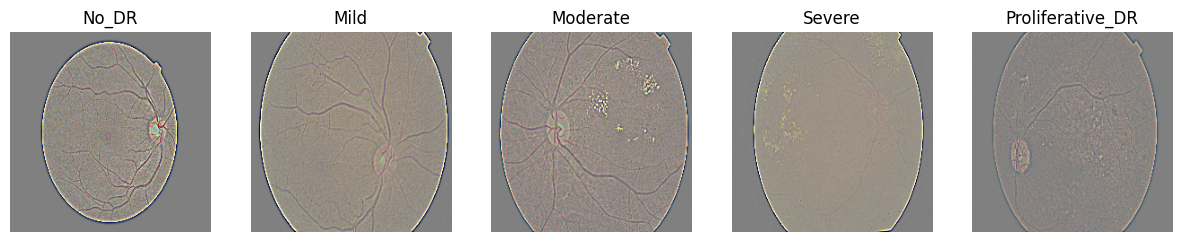

In [7]:
import random
from PIL import Image

plt.figure(figsize=(15, 10))

for i, class_name in enumerate(classes):

    folder = os.path.join(TRAIN_PATH, class_name)

    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    selected_image = random.choice(image_files)

    image_path = os.path.join(folder, selected_image)

    image = Image.open(image_path)

    plt.subplot(1, 5, i + 1)

    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.show()

In [8]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

In [9]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_PATH,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

Found 3229 files belonging to 5 classes.
Using 2584 files for training.


In [10]:
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_PATH,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

Found 3229 files belonging to 5 classes.
Using 645 files for validation.


In [11]:
test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_PATH,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

Found 361 files belonging to 5 classes.


In [12]:
print("Training classes:", train_dataset.class_names)
print("Validation classes:", validation_dataset.class_names)
print("Testing classes:", test_dataset.class_names)

Training classes: ['Mild', 'Moderate', 'No_DR', 'Proliferative_DR', 'Severe']
Validation classes: ['Mild', 'Moderate', 'No_DR', 'Proliferative_DR', 'Severe']
Testing classes: ['Mild', 'Moderate', 'No_DR', 'Proliferative_DR', 'Severe']


In [13]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(
    buffer_size=AUTOTUNE
)

validation_dataset = validation_dataset.prefetch(
    buffer_size=AUTOTUNE
)

test_dataset = test_dataset.prefetch(
    buffer_size=AUTOTUNE
)

In [14]:
from tensorflow.keras.applications import MobileNetV3Small
from tensorflow.keras import layers, models

In [15]:
base_model = MobileNetV3Small(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet",
    include_preprocessing=True
)

base_model.trainable = False

4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [16]:
model = models.Sequential([

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(128, activation='relu'),

    layers.Dense(5, activation='softmax')

])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ MobileNetV3Small (Functional)   │ (None, 7, 7, 576)      │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 576)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,013,621 (3.87 MB)

 Trainable params: 74,501 (291.02 KB)

 Non-trainable params: 939,120 (3.58 MB)

In [17]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),

    loss='categorical_crossentropy',

    metrics=['accuracy']

)

In [18]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = model.fit(

    train_dataset,

    validation_data=validation_dataset,

    epochs=15,

    callbacks=[early_stop]

)

Epoch 1/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 745s 9s/step - accuracy: 0.4303 - loss: 1.4548 - val_accuracy: 0.6140 - val_loss: 1.0617
Epoch 2/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - accuracy: 0.6467 - loss: 1.0257 - val_accuracy: 0.6946 - val_loss: 0.9167
Epoch 3/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 10s 128ms/step - accuracy: 0.6858 - loss: 0.9413 - val_accuracy: 0.7132 - val_loss: 0.8466
Epoch 4/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 11s 130ms/step - accuracy: 0.7032 - loss: 0.8660 - val_accuracy: 0.7256 - val_loss: 0.8078
Epoch 5/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - accuracy: 0.7190 - loss: 0.8176 - val_accuracy: 0.7411 - val_loss: 0.7816
Epoch 6/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 10s 120ms/step - accuracy: 0.7229 - loss: 0.7992 - val_accuracy: 0.7442 - val_loss: 0.7612
Epoch 7/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 11s 130ms/step - accuracy: 0.7287 - loss: 0.7862 - val_accuracy: 0.7380 - val_loss: 0.7494
Epoch 8/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 101ms/step - accuracy: 0.7353 - loss: 0.7665 - val_accuracy:

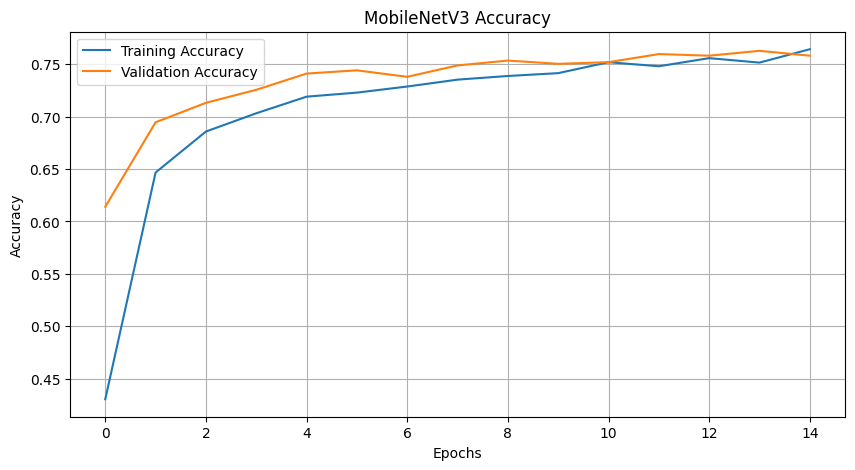

In [19]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('MobileNetV3 Accuracy')

plt.xlabel('Epochs')

plt.ylabel('Accuracy')

plt.legend()

plt.grid()

plt.show()

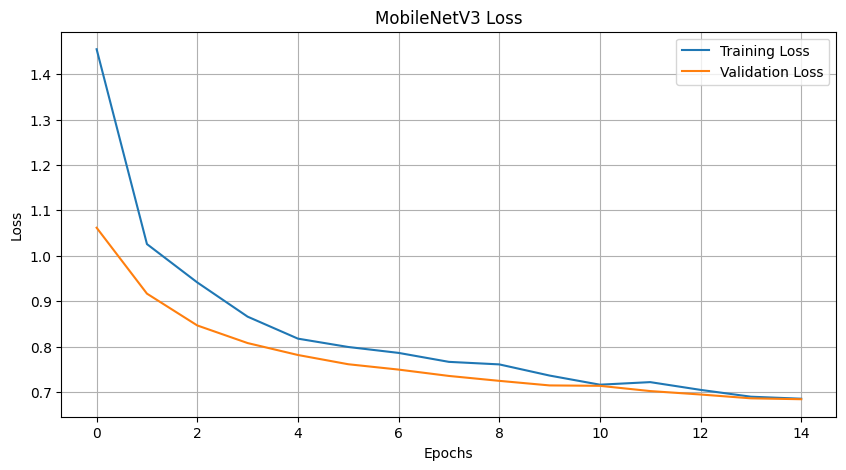

In [20]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('MobileNetV3 Loss')

plt.xlabel('Epochs')

plt.ylabel('Loss')

plt.legend()

plt.grid()

plt.show()

In [21]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", test_loss)

print("Test Accuracy:", test_accuracy * 100, "%")

12/12 ━━━━━━━━━━━━━━━━━━━━ 99s 8s/step - accuracy: 0.7590 - loss: 0.6499
Test Loss: 0.6498852372169495
Test Accuracy: 75.90027451515198 %


In [22]:
import numpy as np

y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_dataset
])

y_pred_prob = model.predict(test_dataset)

y_true = np.argmax(y_true, axis=1)

y_pred = np.argmax(y_pred_prob, axis=1)

print("Actual labels:", y_true[:10])

print("Predicted labels:", y_pred[:10])

12/12 ━━━━━━━━━━━━━━━━━━━━ 9s 415ms/step
Actual labels: [0 0 0 0 0 0 0 0 0 0]
Predicted labels: [0 1 0 0 1 1 2 0 2 1]


In [23]:
from sklearn.metrics import classification_report

class_names = [
    "No_DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative_DR"
]

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

                  precision    recall  f1-score   support

           No_DR       0.42      0.44      0.43        36
            Mild       0.64      0.80      0.71        99
        Moderate       0.91      0.98      0.94       179
          Severe       0.50      0.11      0.18        28
Proliferative_DR       0.00      0.00      0.00        19

        accuracy                           0.76       361
       macro avg       0.49      0.47      0.45       361
    weighted avg       0.71      0.76      0.72       361



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


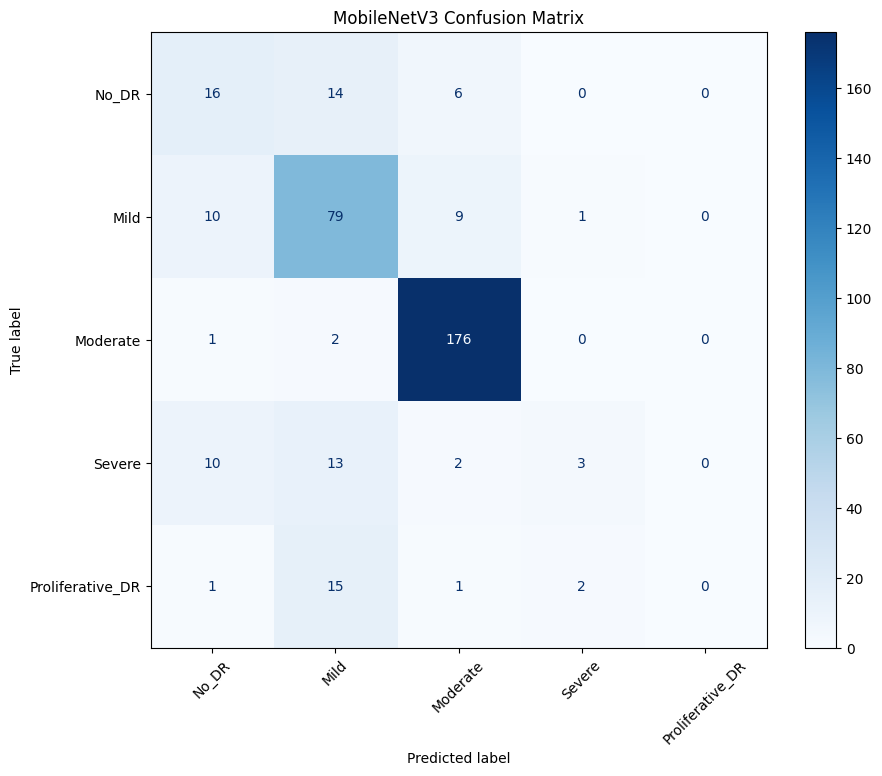

In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    cmap='Blues',
    xticks_rotation=45,
    ax=ax
)

plt.title("MobileNetV3 Confusion Matrix")

plt.show()

In [27]:
import os

folder_path = "/content/drive/MyDrive/DR_Dataset/test/No_DR"

files = os.listdir(folder_path)

print("Total images:", len(files))

print("First 10 image filenames:")

for file in files[:10]:
    print(file)

Total images: 179
First 10 image filenames:
9ac41b9a809e.png
43823561c3f0.png
58eb3809f456.png
75369248dba0.png
4e85aa647534.png
4704dbb59536.png
606daaf0bfc7.png
2a93334f663a.png
0eced86c9db8.png
266fbefa58fb.png


In [28]:
import random
import os

folder_path = "/content/drive/MyDrive/DR_Dataset/test/No_DR"

image_files = [
    f for f in os.listdir(folder_path)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
]

selected_image = random.choice(image_files)

image_path = os.path.join(folder_path, selected_image)

print("Selected image:", image_path)

Selected image: /content/drive/MyDrive/DR_Dataset/test/No_DR/e4d3d437b0a8.png


1/1 ━━━━━━━━━━━━━━━━━━━━ 19s 19s/step


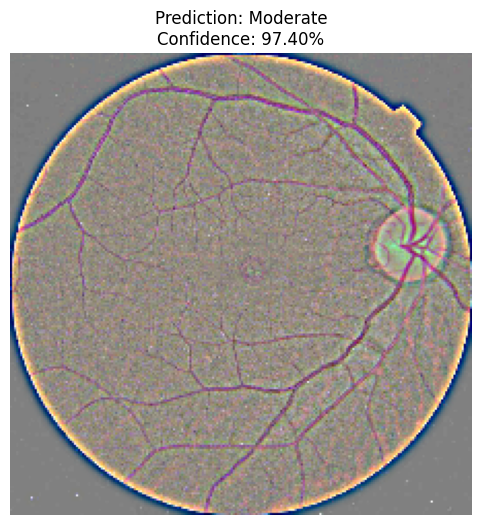

In [29]:
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt

img = load_img(
    image_path,
    target_size=(224, 224)
)

img_array = img_to_array(img)

img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)

predicted_class = class_names[np.argmax(prediction)]

confidence = np.max(prediction) * 100

plt.figure(figsize=(6, 6))

plt.imshow(img)

plt.axis("off")

plt.title(
    f"Prediction: {predicted_class}\nConfidence: {confidence:.2f}%"
)

plt.show()

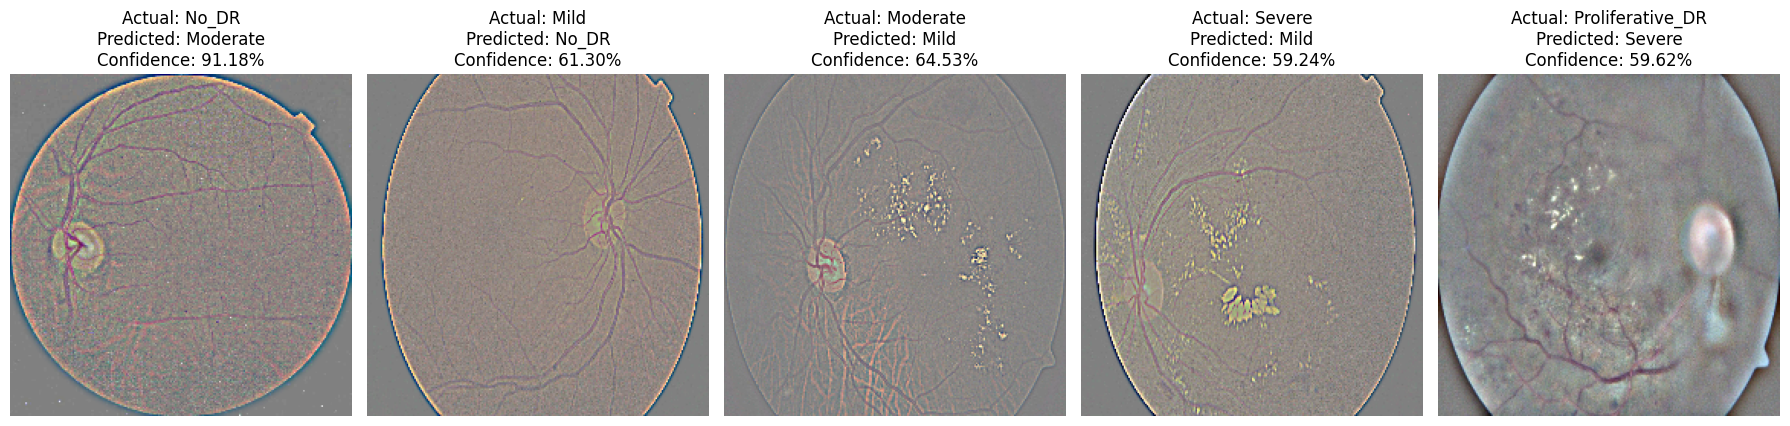

In [30]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img, img_to_array

plt.figure(figsize=(18, 12))

for i, class_name in enumerate(class_names):

    folder = os.path.join(TEST_PATH, class_name)

    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    selected_image = random.choice(image_files)

    image_path = os.path.join(folder, selected_image)

    img = load_img(
        image_path,
        target_size=(224, 224)
    )

    img_array = img_to_array(img)

    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array, verbose=0)

    predicted_class = class_names[np.argmax(prediction)]

    confidence = np.max(prediction) * 100

    plt.subplot(1, 5, i + 1)

    plt.imshow(img)

    plt.title(
        f"Actual: {class_name}\n"
        f"Predicted: {predicted_class}\n"
        f"Confidence: {confidence:.2f}%"
    )

    plt.axis("off")

plt.tight_layout()

plt.show()